<a href="https://colab.research.google.com/github/Hakis3000/tvodo-customizer/blob/main/WaifuTanks_karty_WAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Waifu Tanks – karty (WAI-Illustrious)

Model **WAI-Illustrious** už pozná dievčatá na tankoch (sedí na tanku, v poklope, opretá o pás) – netreba ho nič učiť.
Waifu: sexi uniforma, veľké prsia, veľké oči, mäkký zvodný pohľad. Jedna waifu, jeden tank, jeden celistvý obrázok.

**Postup:**
1. Runtime → Change runtime type → **L4** → Save.
2. Spusti **bunku 1** (raz za reláciu, cca 5 min). Spýta sa na **Civitai API kľúč** – vlož ho (civitai.com → Settings → API Keys → Add). Ak ho nemáš, len stlač Enter – použije sa záložná kópia modelu.
3. Spusti **bunku 2** (nastavenia štýlu – nemeniť).
4. **Bunka 3:** vyber kartu a dievča v roletkách → spusti. Opakuj koľkokrát chceš.
5. **Bunka 4:** všetky karty za jednu stranu naraz. **Bunka 5:** variácie z dobrého obrázka.

Obrázky sa ukladajú na Drive do `WaifuTanks/karty/<GE|SU>/<karta>/`. Na konci: Runtime → Disconnect and delete runtime.

In [ ]:
#@title 1. Príprava (raz za reláciu)
!pip -q install -U diffusers transformers accelerate safetensors
import os, random, requests, getpass, torch, IPython.display as D
from PIL import Image
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/WaifuTanks/karty'; os.makedirs(OUT, exist_ok=True)
from diffusers import StableDiffusionXLPipeline, StableDiffusionXLImg2ImgPipeline, EulerAncestralDiscreteScheduler

KEY = getpass.getpass('Civitai API kľúč (Enter = bez kľúča): ').strip()
pipe = None
if KEY:
    try:   # najnovšia verzia WAI-Illustrious z Civitai
        info = requests.get('https://civitai.com/api/v1/models/827184', timeout=30).json()
        ver = info['modelVersions'][0]; url = ver['downloadUrl']
        path = f"/content/wai_{ver['id']}.safetensors"
        if not os.path.exists(path):
            print('sťahujem', info['name'], ver['name'], '…')
            !wget -q -O "{path}" "{url}?token={KEY}"
        pipe = StableDiffusionXLPipeline.from_single_file(path, torch_dtype=torch.float16)
        print('model:', info['name'], ver['name'])
    except Exception as e:
        print('Civitai nevyšlo (', e, ') – použijem záložnú kópiu'); pipe = None
if pipe is None:   # kópie WAI-Illustrious na Hugging Face (bez Civitai) – skúsi novšiu, potom staršiu
    for repo in ['John6666/wai-nsfw-illustrious-v90-sdxl', 'John6666/wai-nsfw-illustrious-v70-sdxl']:
        try:
            pipe = StableDiffusionXLPipeline.from_pretrained(repo, torch_dtype=torch.float16); print('model:', repo); break
        except Exception as e: print('nedostupné:', repo)
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
pipe.to('cuda'); pipe.vae.enable_tiling()
i2i = StableDiffusionXLImg2ImgPipeline(vae=pipe.vae, text_encoder=pipe.text_encoder, text_encoder_2=pipe.text_encoder_2,
        tokenizer=pipe.tokenizer, tokenizer_2=pipe.tokenizer_2, unet=pipe.unet, scheduler=pipe.scheduler)

# ---- dlhé prompty: rozdelí tagy na kúsky po 75 tokenov (model inak číta len začiatok)
@torch.no_grad()
def _enc(text):
    tags = [t.strip() for t in text.split(',') if t.strip()]
    chunks, cur = [], []
    for t in tags:
        if cur and len(pipe.tokenizer(', '.join(cur + [t])).input_ids) - 2 > 75: chunks.append(', '.join(cur)); cur = [t]
        else: cur.append(t)
    chunks.append(', '.join(cur))
    embs, pooled = [], None
    for ch in chunks:
        a = pipe.tokenizer(ch, padding='max_length', max_length=77, truncation=True, return_tensors='pt').input_ids.to('cuda')
        b = pipe.tokenizer_2(ch, padding='max_length', max_length=77, truncation=True, return_tensors='pt').input_ids.to('cuda')
        o1 = pipe.text_encoder(a, output_hidden_states=True); o2 = pipe.text_encoder_2(b, output_hidden_states=True)
        if pooled is None: pooled = o2[0]
        embs.append(torch.cat([o1.hidden_states[-2], o2.hidden_states[-2]], -1))
    return embs, pooled
@torch.no_grad()
def embeds(pos, neg):
    pe, pp = _enc(pos); ne, npool = _enc(neg)
    empty, _ = _enc(' ')
    while len(pe) < len(ne): pe.append(empty[0])
    while len(ne) < len(pe): ne.append(empty[0])
    return dict(prompt_embeds=torch.cat(pe, 1), pooled_prompt_embeds=pp, negative_prompt_embeds=torch.cat(ne, 1), negative_pooled_prompt_embeds=npool)
print('✅ pripravené')

In [34]:
#@title 2. Štýl, dievčatá a karty
QUALITY = 'masterpiece, best quality, amazing quality, very aesthetic, absurdres, detailed eyes, detailed face, high detail'
# štýl podľa predlôh v ref: anime dievča + detailný, skoro realistický tank, zlatá hodinka, teplé svetlo, zemité farby
STYLE = ('anime illustration, anime girl, detailed realistic ww2 tank, semi-realistic tank, soft painterly shading, '
         'golden hour, warm sunset lighting, cinematic lighting, dramatic clouds, detailed background, grass field, '
         'earthy military colors, weathered metal, mud on tank, dust, soft shadows, depth')
NEG = ('bad quality, worst quality, worst detail, low quality, lowres, sketch, censor, bad anatomy, bad hands, extra digits, fewer digits, '
       'missing fingers, extra arms, extra legs, text, signature, watermark, username, multiple girls, 2girls, 3girls, '
       'photorealistic, photo, 3d, render, monochrome, desaturated, grey background, simple background, '
       'pastel colors, pastel, washed out, toy tank, cartoon tank, chibi tank, cute tank, blue tank, pink tank, purple tank, clean shiny tank, plastic, '
       'one eye closed, wink, closed eyes, '
       'sharp eyes, narrow eyes, tsurime, glaring, angry, serious, frown, small eyes, small breasts, flat chest, fat, chubby, '
       'muscular female, bodybuilder, veins, gigantic breasts, crotch focus, from below, '
       'giantess, girl larger than tank, oversized girl, '
       'swastika, nazi, armband, girls und panzer, multiple tanks, tank in background, distant tank, fantasy tank, futuristic tank, modern tank, sci-fi, mecha')

# tvár: anime oči, zvodný pohľad (obe oči otvorené)
FACE = 'large eyes, anime eyes, sparkling eyes, detailed eyes, long eyelashes, both eyes open, half-closed eyes, blush, seductive smile, parted lips, looking at viewer'
# postava: veľké prsia, štíhly pás, jemné bruško, vyšportované nohy a zadok (SEXI 1–3)
BODY = {1: 'mature female, large breasts, cleavage, slim waist, toned stomach, athletic legs, thighs',
        2: 'mature female, huge breasts, cleavage, slim waist, toned stomach, slight abs, athletic legs, thighs, round ass, curvy, seductive pose',
        3: 'mature female, huge breasts, deep cleavage, narrow waist, toned stomach, slight abs, athletic legs, thick thighs, round ass, wide hips, curvy, seductive pose, arched back'}
# oblečenie: od skoro ničoho po sexi kabátik – vyberieš v bunke 3 (alebo náhodne)
COL = {'GE': dict(c='black', j='black', t='red'), 'SU': dict(c='red', j='olive green', t='red')}
OUTFITS = {
  '1 mikro – skoro nič':  '{c} sling bikini, slingshot swimsuit, {j} military cap, black thighhighs, black gloves',
  '2 micro bikiny':       '{c} micro bikini, string bikini, {j} military cap, black thighhighs, garter straps, black gloves',
  '3 bikiny + kabátik':   '{c} micro bikini, string bikini, cropped {j} military jacket, open jacket, black thighhighs, garter straps, black gloves',
  '4 kabátik s výrezom':  '{j} military uniform, cropped military jacket, cleavage cutout, clothing cutout, plunging neckline, underbust, {t} collar, {t} trim, gold buttons, midriff, {j} microskirt, pleated microskirt, {c} thong, highleg panties, panty peek, black thighhighs, garter straps, black gloves',
  '5 rozopnutá uniforma': '{j} military uniform, unbuttoned military jacket, open jacket, no shirt, {c} bra, cleavage, midriff, {j} pencil skirt, side slit, black pantyhose, black gloves',
  '7 ako na predlohách': 'black cropped military jacket, open jacket, {c} bra, cleavage, midriff, black pleated miniskirt, garter straps, black thighhighs, black fingerless gloves, military cap with goggles',
  '6 sexi uniforma':      '{j} military uniform, tight military jacket, partially unbuttoned, cleavage, {t} trim, gold buttons, {j} miniskirt, black thighhighs, zettai ryouiki, black gloves',
}
def outfit(name, side):
    return OUTFITS[name].format(**COL[side])

GIRLS = {
  'Lili':    ('GE', 'long wavy light brown hair, brown eyes, grey garrison cap, black hair ribbons'),
  'Greta':   ('GE', 'long wavy pink hair, green eyes, black peaked cap'),
  'Hanna':   ('GE', 'short black bob hair, amber eyes, tan skin, red headband'),
  'Frieda':  ('GE', 'orange hair, twin braids, freckles, blue eyes, goggles on head'),
  'Mitzi':   ('GE', 'short silver hair, purple eyes, round eyewear, headphones'),
  'Elsa':    ('GE', 'long dark blue hair, ponytail, grey eyes, grey garrison cap'),
  'Katyuša': ('SU', 'long blonde hair, green eyes, ushanka, red star, red ribbon'),
  'Zoja':    ('SU', 'long straight black hair, light blue eyes, side cap, scarf'),
  'Nataša':  ('SU', 'brown hair, blue eyes'),
  'Daša':    ('SU', 'short red hair, green eyes, tank helmet'),
  'Mila':    ('SU', 'chestnut hair, twin braids, red bow, brown eyes, headphones'),
}
# tanky z hry – na začiatku meno, ktoré model pozná (zo seriálov a fan artu), potom tvar
# ✔ = model pozná dobre   ~ = pozná slabo, pomáha príbuzný tank + popis
TANKS = {
  'Panzer III J': ('GE', 'panzerkampfwagen iii, panzer iii, german medium tank, boxy hull, small square turret, short 50mm gun, six small road wheels, grey'),            # ✔
  'Panzer IV G':  ('GE', 'panzerkampfwagen iv, panzer iv, german medium tank, boxy hull, square turret with side hatches, long 75mm gun with muzzle brake, eight small road wheels, grey'),  # ✔
  'StuG III G':   ('GE', 'sturmgeschutz iii, stug iii, german assault gun, no turret, low flat casemate, long 75mm gun in hull front, six small road wheels, grey'),        # ✔
  'Panther':      ('GE', 'panther (tank), panther, german medium tank, sloped front armor, rounded turret, long 75mm gun with muzzle brake, large interleaved road wheels, dark yellow'),  # ✔
  'Tiger I':      ('GE', 'tiger i, german heavy tank, boxy hull, large box turret, long 88mm gun with muzzle brake, large interleaved road wheels, dark yellow'),              # ✔
  'Ferdinand':    ('GE', 'elefant, ferdinand, german tank destroyer, no turret, large boxy casemate at the rear, very long 88mm gun, six large road wheels, dark yellow'),     # ✔
  'T-34/76 A':    ('SU', 't-34, t-34/76, soviet medium tank, sloped armor, small rounded turret, short 76mm gun, five large road wheels, green'),                              # ✔
  'T-34/76 D':    ('SU', 't-34, t-34/76, soviet medium tank, sloped armor, hexagonal turret with two round hatches, 76mm gun, five large road wheels, green'),              # ✔
  'T-34-85':      ('SU', 't-34-85, soviet medium tank, sloped armor, large turret, long 85mm gun, five large road wheels, green'),                                           # ✔
  'KV-85':        ('SU', 'kv-1, kv-85, soviet heavy tank, boxy heavy hull, large rounded cast turret, 85mm gun, six small road wheels, green'),                                 # ~
  'SU-100':       ('SU', 't-34 chassis, su-100, soviet tank destroyer, no turret, sloped casemate, very long 100mm gun, five large road wheels, green'),                        # ~
  'IS-2':         ('SU', 'is-2, soviet heavy tank, large rounded turret, very long thick 122mm gun with muzzle brake, six road wheels, green'),                                # ✔
}

# ZÁBER – aký veľký je tank v obrázku
SHOTS = {
  'detail veže': ('tank turret close-up, on top of tank turret, turret hatch, cannon barrel, girl on turret, full body, from side', (1024, 1024)),
  'celý tank':   ('very wide shot, scenery, whole tank visible, caterpillar tracks, tank focus, size difference, small figure, full body, from side', (1216, 832)),
  'v poklope':   ('tank turret close-up, girl in turret hatch, upper body out of hatch, cannon barrel, from side', (1024, 1024)),
}
# PÓZA – čo robí na tanku
POSES = {
  'sedí':        'sitting on tank turret, sitting, crossed legs',
  'kľačí':       'kneeling on tank turret, kneeling, hands on thighs',
  'leží':        'lying on tank turret, lying on stomach, legs up, chin rest',
  'opiera sa':   'leaning on cannon barrel, leaning back, hand behind head',
  'stojí':       'standing on tank turret, hand on hip, contrapposto',
  'v poklope':   'in turret hatch, upper body out of hatch, arms on hatch rim',
}
# karta: (kľúč, dievča za Nemcov, dievča za Sovietov, predvolená póza, čo sa deje okolo)
CARDS = {
  'Pohyb':    ('move',       'Frieda', 'Daša',    'v poklope', 'driving, mud splash, waving, laughing'),
  'Paľba':    ('fire',       'Greta',  'Zoja',    'sedí',      'firing, muzzle flash, smoke, covering ears, surprised'),
  'Obchvat':  ('flank',      'Lili',   'Katyuša', 'stojí',     'pointing forward, ruined village, dust'),
  'Les':      ('woods',      'Lili',   'Katyuša', 'sedí',      'forest, sunlight through trees'),
  'Bahno':    ('mud',        'Frieda', 'Daša',    'kľačí',     'stuck in mud, mud on body, embarrassed, pout'),
  'Pole':     ('field',      'Hanna',  'Nataša',  'opiera sa', 'wheat field, sunset, wind'),
  'Taktika':  ('tactics',    'Mitzi',  'Mila',    'leží',      'holding map, pencil, thinking, smile'),
  'Velenie':  ('leadership', 'Lili',   'Katyuša', 'v poklope', 'commander, holding binoculars, smile, blue sky'),
  'Rozkaz':   ('command',    'Mitzi',  'Mila',    'kľačí',     'headphones, holding microphone, salute'),
  'Dym':      ('smoke',      'Greta',  'Zoja',    'stojí',     'smoke, smoke screen, mischievous smile'),
  'Roklina':  ('gully',      'Hanna',  'Nataša',  'sedí',      'ravine, rocks'),
  'Budova':   ('building',   'Elsa',   'Nataša',  'opiera sa', 'ruined building, brick wall'),
  'Sutiny':   ('rubble',     'Elsa',   'Nataša',  'kľačí',     'rubble, destroyed city, dust'),
  'Rub karty':('back',       'Lili',   'Katyuša', 'sedí',      'looking back, over shoulder, from behind, rim light, ornate border'),
}
def build(card, side, girl=None, sexi=2, extra='', obl='4 kabátik s výrezom', zaber='detail veže', poza='podľa karty', tank='Panzer IV G'):
    key, ge, su, pdef, scene = CARDS[card]
    g = girl or (ge if side == 'GE' else su)
    gs, look = GIRLS[g]
    shot, size = SHOTS[zaber]
    pose = POSES[pdef if poza == 'podľa karty' else poza]
    if tank not in TANKS: raise ValueError(f'Neznámy tank: {tank} – vyber jeden zo zoznamu TANKS')
    tank_tags = TANKS[tank][1]
    # STRIKTNE: zvolený tank 2× v prompte, všetky ostatné tanky z hry v zákazoch
    t0 = tank_tags.split(',')[0]
    others = ', '.join(sorted({v[1].split(',')[0] for v in TANKS.values() if v[1].split(',')[0] not in t0 and t0 not in v[1].split(',')[0]}))
    p = ', '.join(x for x in ['1girl, solo', shot, 'tank, military vehicle, ' + tank_tags, pose, scene, look, outfit(obl, gs), BODY[sexi], FACE, extra,
                              'only one tank, ' + tank_tags.split(',')[0], STYLE, QUALITY] if x)
    neg = NEG + ', ' + others + ('' if zaber == 'v poklope' else ', upper body, portrait, cowboy shot, close-up of girl')
    if key == 'back': size = (896, 1248)
    return key, g, p, neg, size
print('štýl načítaný:', len(GIRLS), 'dievčat,', len(CARDS), 'kariet,', len(TANKS), 'tankov,', len(SHOTS), 'zábery,', len(POSES), 'pózy')

štýl načítaný: 11 dievčat, 14 kariet, 12 tankov, 3 zábery, 6 pózy


štýl podľa 8 obrázkov · sila 0.5


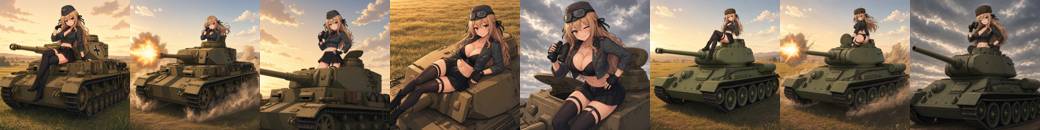

In [35]:
#@title 2b. Štýl kresby podľa predlôh v priečinku ref
STYL = 'predlohy v ref'  #@param ['žiadny', 'predlohy v ref', 'Kat', 'Lili']
SILA_STYLU = 0.5  #@param {type:"slider", min:0.2, max:1.0, step:0.05}
# 'predlohy v ref' = vybrané obrázky z Google Drive: WaifuTanks/ref/ (dievča na tanku, zlatá hodinka)
# Prenesie sa ŠTÝL KRESBY (tvár, oči, farby, svetlo, tanky) – nie presná póza.
import glob, os
R = '/content/drive/MyDrive/WaifuTanks/ref'
VYBER = ['sand-save-1794409867139.jpg', 'sand-save-1794411498446.jpg', 'sand-save-1794411503006.jpg', 'sand-save-1794413877667.jpg',
         'sand-save-1794413887795.jpg', 'sand-save-1794415166138.jpg', 'sand-save-1794415169046.jpg', 'sand-save-1794415183812.jpg']
if STYL == 'žiadny':
    if globals().get('IP_ON'): pipe.unload_ip_adapter(); IP_ON = False
    STYLE_KW = {}
    print('štýl: len z promptu')
else:
    if STYL == 'predlohy v ref':
        paths = [f'{R}/{n}' for n in VYBER if os.path.exists(f'{R}/{n}')]
        if not paths:   # ak sa názvy nezhodujú, vezme prvých 8 obrázkov z priečinka
            paths = sorted(p for p in glob.glob(f'{R}/*') if p.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')))[:8]
    else:
        paths = [f'{R}/{"kat.png" if STYL == "Kat" else "lili.png"}']
    if not paths: raise FileNotFoundError(f'V priečinku {R} nie sú žiadne obrázky')
    if not globals().get('IP_ON'):
        pipe.load_ip_adapter('h94/IP-Adapter', subfolder='sdxl_models', weight_name='ip-adapter_sdxl.safetensors'); IP_ON = True
    pipe.set_ip_adapter_scale({'up': {'block_0': [0.0, SILA_STYLU, 0.0]}})   # len štýl, nie obsah (InstantStyle)
    refs = [Image.open(p).convert('RGB') for p in paths]
    STYLE_KW = dict(ip_adapter_image=[refs])
    print(f'štýl podľa {len(refs)} obrázkov · sila {SILA_STYLU}')
    row = Image.new('RGB', (130 * len(refs), 130), 'white')
    for k, r in enumerate(refs): r2 = r.copy(); r2.thumbnail((130, 130)); row.paste(r2, (130 * k, 0))
    D.display(row)

In [ ]:
#@title 3. Jedna karta
KARTA = 'Les'  #@param ['Pohyb', 'Paľba', 'Obchvat', 'Les', 'Bahno', 'Pole', 'Taktika', 'Velenie', 'Rozkaz', 'Dym', 'Roklina', 'Budova', 'Sutiny', 'Rub karty']
STRANA = 'Nemci'  #@param ['Nemci', 'Sovieti']
DIEVCA = 'podľa karty'  #@param ['podľa karty', 'Lili', 'Greta', 'Hanna', 'Frieda', 'Mitzi', 'Elsa', 'Katyuša', 'Zoja', 'Nataša', 'Daša', 'Mila']
TANK = 'Tiger I'  #@param ['Panzer III J', 'Panzer IV G', 'StuG III G', 'Panther', 'Tiger I', 'Ferdinand', 'T-34/76 A', 'T-34/76 D', 'T-34-85', 'KV-85', 'SU-100', 'IS-2']
ZABER = 'detail veže'  #@param ['detail veže', 'celý tank', 'v poklope']
POZA = 'podľa karty'  #@param ['podľa karty', 'sedí', 'kľačí', 'leží', 'opiera sa', 'stojí', 'v poklope']
OBLECENIE = '7 ako na predlohách'  #@param ['náhodné', '1 mikro – skoro nič', '2 micro bikiny', '3 bikiny + kabátik', '4 kabátik s výrezom', '5 rozopnutá uniforma', '6 sexi uniforma', '7 ako na predlohách']
VARIANTY = 4  #@param {type:"slider", min:1, max:8, step:1}
SEXI = 2  #@param {type:"slider", min:1, max:3, step:1}
NAVYSE = ''  #@param {type:"string"}
VYLEPSIT = True  #@param {type:"boolean"}
# TANK: vždy sa použije presne tento tank (ostatné tanky z hry sú zakázané)
# ZABER: detail veže = priblížená veža, dievča na nej | celý tank = celý tank, dievča menšie | v poklope = vykláňa sa z poklopu
# VYLEPSIT = druhé prekreslenie vo väčšom rozlíšení (ostrejšia tvár, oči, detaily) – trvá 2× dlhšie
# OBLECENIE 'náhodné' = každý variant v inom oblečení; číslo je v názve súboru a pod obrázkom

def hires(im, E, s):   # zväčší 1,5× a prekreslí detaily (tvár, oči, ruky) – rovnaká kompozícia
    big = im.resize((int(im.width * 1.5) // 8 * 8, int(im.height * 1.5) // 8 * 8), Image.LANCZOS)
    up = StableDiffusionXLImg2ImgPipeline(**pipe.components)
    return up(**E, **globals().get('STYLE_KW', {}), image=big, strength=0.4, num_inference_steps=30, guidance_scale=6.0,
              generator=torch.Generator('cuda').manual_seed(s)).images[0]

def gen(card, side, girl=None, n=4, sexi=2, extra='', obl='náhodné', zaber='detail veže', poza='podľa karty', tank='Tiger I', seed=None, better=True):
    ims = []
    for i in range(n):
        o = random.choice(list(OUTFITS)) if obl == 'náhodné' else obl
        key, g, prompt, neg, (w, h) = build(card, side, girl, sexi, extra, o, zaber, poza, tank)
        os.makedirs(f'{OUT}/{side}/{key}', exist_ok=True)
        s = seed if seed is not None else random.randint(0, 2**31 - 1)
        E = embeds(prompt, neg)
        im = pipe(**E, **globals().get('STYLE_KW', {}), width=w, height=h, num_inference_steps=28, guidance_scale=6.0,
                  generator=torch.Generator('cuda').manual_seed(s)).images[0]
        if better: im = hires(im, E, s)
        p = f'{OUT}/{side}/{key}/{key}_{g}_obl{o[0]}_{s}.png'; im.save(p); ims.append(im)
        print(f'  {i + 1}. oblečenie {o} → {p}')
    W = 300; H = int(W * ims[0].height / ims[0].width)
    grid = Image.new('RGB', (W * len(ims), H))
    for k, im in enumerate(ims): grid.paste(im.resize((W, H)), (W * k, 0))
    D.display(grid)

side = 'GE' if STRANA == 'Nemci' else 'SU'
gen(KARTA, side, None if DIEVCA == 'podľa karty' else DIEVCA, VARIANTY, SEXI, NAVYSE, OBLECENIE, ZABER, POZA, TANK, better=VYLEPSIT)

  0%|          | 0/28 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/12 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  1. oblečenie 7 ako na predlohách → /content/drive/MyDrive/WaifuTanks/karty/GE/woods/woods_Lili_obl7_51429894.png


  0%|          | 0/28 [00:00<?, ?it/s]

... (6 outputs left out)

  0%|          | 0/12 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  3. oblečenie 7 ako na predlohách → /content/drive/MyDrive/WaifuTanks/karty/GE/woods/woods_Lili_obl7_1409286575.png


  0%|          | 0/28 [00:00<?, ?it/s]

In [ ]:
#@title 4. Všetky karty za jednu stranu (cca 30–40 min)
STRANA = 'Nemci'  #@param ['Nemci', 'Sovieti']
VARIANTY = 4  #@param {type:"slider", min:1, max:8, step:1}
SEXI = 2  #@param {type:"slider", min:1, max:3, step:1}
side = 'GE' if STRANA == 'Nemci' else 'SU'
for card in CARDS:
    print('—', card); gen(card, side, None, VARIANTY, SEXI, '', 'náhodné', 'detail veže')

In [ ]:
#@title 5. Variácie z dobrého obrázka
CESTA = ''  #@param {type:"string"}
KARTA = 'Velenie'  #@param ['Pohyb', 'Paľba', 'Obchvat', 'Les', 'Bahno', 'Pole', 'Taktika', 'Velenie', 'Rozkaz', 'Dym', 'Roklina', 'Budova', 'Sutiny', 'Rub karty']
STRANA = 'Nemci'  #@param ['Nemci', 'Sovieti']
ZMENA = 0.6  #@param {type:"slider", min:0.3, max:0.85, step:0.05}
VARIANTY = 4  #@param {type:"slider", min:1, max:8, step:1}
# CESTA: vľavo priečinok 📁 → drive/MyDrive/WaifuTanks/karty/… → pravý klik na obrázok → Copy path → vlož sem
# ZMENA: 0.4 = skoro rovnaký, 0.6 = iná póza v rovnakom štýle, 0.8 = skoro nový obrázok
side = 'GE' if STRANA == 'Nemci' else 'SU'
key, g, prompt, neg, _ = build(KARTA, side)
src = Image.open(CESTA).convert('RGB'); E = embeds(prompt, neg); ims = []
for i in range(VARIANTY):
    s = random.randint(0, 2**31 - 1)
    im = i2i(**E, image=src, strength=ZMENA, num_inference_steps=32, guidance_scale=6.0, generator=torch.Generator('cuda').manual_seed(s)).images[0]
    p = f'{OUT}/{side}/{key}/{key}_{g}_var{s}.png'; im.save(p); ims.append(im); print('  uložené:', p)
grid = Image.new('RGB', (300 * len(ims), 300))
for k, im in enumerate(ims): grid.paste(im.resize((300, 300)), (300 * k, 0))
D.display(grid)

In [ ]:
import os
print('Drive pripojený:', os.path.ismount('/content/drive'))
d = f'{OUT}/GE'
for root, dirs, fs in os.walk(d):
    if fs: print(root, '→', len(fs), 'obrázkov')